In [1]:
# Kết nối Google Colab vào Google Drive
from google.colab import drive
drive.mount("/content/drive")
# Chuyển đến thư mục làm việc
%cd /content/drive/MyDrive/Gradient

Mounted at /content/drive
/content/drive/MyDrive/Gradient


In [2]:
!ls

 advertising.csv  'bath_gradient_descent (1).ipynb'   bath_gradient_descent.ipynb


In [14]:
import numpy as np
import pandas as pd

# Load the data
data = pd.read_csv('advertising.csv')  # Giả sử bạn đã lưu dữ liệu vào file 'advertising.csv'
X = data[['TV', 'Radio', 'Newspaper']].values  # Các đặc trưng đầu vào
y = data['Sales'].values  # Nhãn đầu ra

# Chuẩn hóa dữ liệu
X = (X - X.mean(axis=0)) / X.std(axis=0)  # Standardize features
X = np.c_[np.ones(X.shape[0]), X]  # Thêm cột bias (x_0 = 1) vào X
y = y.reshape(-1, 1)


In [15]:
def compute_cost(X, y, theta):
    """Tính chi phí (cost function)"""
    m = len(y)
    predictions = X.dot(theta)
    cost = (1/(2*m)) * np.sum((predictions - y) ** 2)
    return cost

def compute_gradient(X, y, theta):
    """Tính gradient"""
    m = len(y)
    predictions = X.dot(theta)
    gradients = (1/m) * X.T.dot(predictions - y)
    return gradients


In [16]:
def gradient_descent(X, y, theta, learning_rate, num_iters):
    """Thuật toán Gradient Descent (GD) cơ bản"""
    cost_history = []

    for i in range(num_iters):
        gradients = compute_gradient(X, y, theta)
        theta = theta - learning_rate * gradients
        cost = compute_cost(X, y, theta)
        cost_history.append(cost)

    return theta, cost_history


In [17]:
def gd_with_momentum(X, y, theta, learning_rate, num_iters, beta):
    """GD with Momentum"""
    cost_history = []
    v = np.zeros(theta.shape)  # Tốc độ ban đầu bằng 0

    for i in range(num_iters):
        gradients = compute_gradient(X, y, theta)
        v = beta * v + learning_rate * gradients  # Cập nhật vận tốc
        theta = theta - v  # Cập nhật theta
        cost = compute_cost(X, y, theta)
        cost_history.append(cost)

    return theta, cost_history


In [18]:
def nag(X, y, theta, learning_rate, num_iters, beta):
    """Nesterov Accelerated Gradient"""
    cost_history = []
    v = np.zeros(theta.shape)

    for i in range(num_iters):
        look_ahead_theta = theta - beta * v  # Ước tính trước
        gradients = compute_gradient(X, y, look_ahead_theta)  # Tính gradient tại điểm ước tính
        v = beta * v + learning_rate * gradients  # Cập nhật vận tốc
        theta = theta - v  # Cập nhật theta
        cost = compute_cost(X, y, theta)
        cost_history.append(cost)

    return theta, cost_history


In [19]:
# Khởi tạo tham số
theta = np.zeros((X.shape[1], 1))
learning_rate = 0.01
num_iters = 1000
beta = 0.9  # Hệ số momentum

# Gradient Descent
theta_gd, cost_history_gd = gradient_descent(X, y, theta, learning_rate, num_iters)

# GD with Momentum
theta_momentum, cost_history_momentum = gd_with_momentum(X, y, theta, learning_rate, num_iters, beta)

# NAG
theta_nag, cost_history_nag = nag(X, y, theta, learning_rate, num_iters, beta)


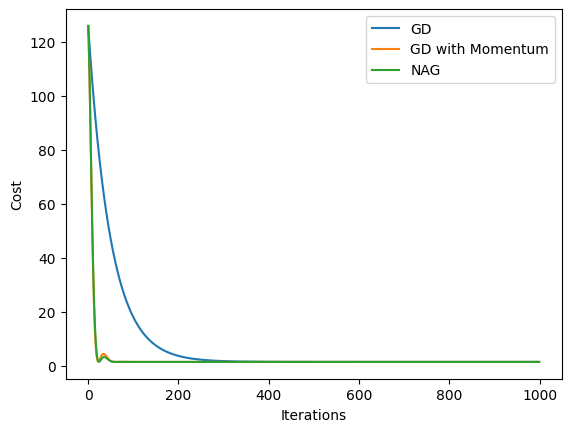

In [20]:
import matplotlib.pyplot as plt

plt.plot(range(num_iters), cost_history_gd, label='GD')
plt.plot(range(num_iters), cost_history_momentum, label='GD with Momentum')
plt.plot(range(num_iters), cost_history_nag, label='NAG')
plt.xlabel('Iterations')
plt.ylabel('Cost')
plt.legend()
plt.show()


In [21]:
# Chạy với m = 1, m = 20, m = 150
X_m1 = X[:1, :]
y_m1 = y[:1]
X_m20 = X[:20, :]
y_m20 = y[:20]
X_m150 = X[:150, :]
y_m150 = y[:150]

# Lặp lại các bước ở trên cho mỗi bộ dữ liệu để kiểm tra hiệu quả
